# 04 · Nonlinear (kernel) Granger causality between media coverage and search interest

Notebook 03 tested **linear** Granger causality. This notebook asks whether **nonlinear**
predictive links exist between MediaCloud coverage (MC) and Google Trends interest (GT),
in each direction, with the two constraint-based kernel methods reviewed and unified by
**Murphy & Benavoli (2026), "Constraint- and Score-Based Nonlinear Granger Causality
Discovery with Kernels", arXiv:2601.09579**:

| Method | Idea | Decision rule in the original papers |
|---|---|---|
| **KGC**, kernel Granger causality (Marinazzo, Pellicoro & Stramaglia, 2008) | project the effect on its own past in a kernel space, then correlate what is left with the new directions brought by the cause | correlations significant after Bonferroni ($\delta_f > 0$) |
| **lsNGC**, large-scale nonlinear Granger causality (Wismüller et al., 2021) | nonlinear features of each block (Gaussian radial basis functions around k-means centres), then compare least-squares fits with and without the cause | F-test, false discovery rate control |

KGC uses the squared-exponential (SE) kernel with the lengthscale heuristic of the paper
($l = 2\times$ number of inputs). It is also run with a polynomial kernel of degree 1, which
reduces it exactly to **linear** Granger causality, as a reference.

### What this notebook adds for campaign data

Both methods assume that no unobserved variable drives both series. Here one does: **the
campaign calendar** raises press coverage and searches at the same dates. So:

1. **Lags never cross seasons.** Each lagged value comes from the same campaign window.
2. **Season-swap surrogates.** Under the null, the cause series of each season is replaced
   by that of *another* season, aligned by day of the window. The surrogate keeps the
   cause's own dynamics and its campaign-shaped profile, but loses its day-to-day link
   with the effect. A link is retained only if the real cause does better than 199 such
   surrogates.
3. **Calendar conditioning (variant).** Day in the window and day of the week are added to
   both models, so that the cause must add information beyond a fixed calendar profile.
4. **Validation on simulations** with a known truth, including common drivers, before
   looking at real data.

**What remains out of reach.** A common driver whose timing changes from one year to the
next (a campaign launched on a different day each year, a celebrity announcement…) still
links both series within a season. Section 2 shows that no test here removes it. Results
are therefore evidence of **predictive links beyond a fixed campaign calendar**, not proof
of a direct causal effect.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "phc").exists())
sys.path.insert(0, str(ROOT / "src"))

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from phc.config import CAMPAIGNS, FIG_DIR, TAB_DIR
from phc.granger import load_daily
from phc import kernel_granger as K
from phc import simulate as S

# ---- parameters -----------------------------------------------------------
RECOMPUTE = False        # False: reuse results/cache/kernel_granger.joblib if it exists
N_JOBS = -1              # parallel workers (-1 = all cores)
N_SURR = 199             # season-swap surrogates, real data (p-value resolution 0.005)
N_SURR_SIM = 99          # surrogates, single simulated dataset per scenario
N_SURR_RATE = 39         # surrogates, rejection-rate study (resolution 0.025)
RATE_SEEDS = range(12)   # simulated datasets per scenario in the rejection-rate study
LAGS = (1, 2, 3, 5, 7)   # lag orders compared
START = max(LAGS)        # first target day of each season (same sample for every lag)
ALPHA = 0.05

CODES = ["DJ", "MB", "Mov", "OR"]
LABEL = {c: CAMPAIGNS[c].label for c in CODES}
DIRS = [("gt", "mc", "MC → GT"), ("mc", "gt", "GT → MC")]     # (effect, cause, label)
METHODS = {"kgc_lin": "Linear Granger", "kgc_se": "KGC (SE kernel)", "lsngc": "lsNGC"}

CACHE = ROOT / "results" / "cache" / "kernel_granger.joblib"
CACHE.parent.mkdir(parents=True, exist_ok=True)
cache = joblib.load(CACHE) if (CACHE.exists() and not RECOMPUTE) else {}


def cached(key, fn):
    """Compute fn() once and store the result in the cache file."""
    if key not in cache:
        t = time.time()
        cache[key] = fn()
        joblib.dump(cache, CACHE)
        print(f"[{key}] computed in {time.time() - t:.0f}s")
    else:
        print(f"[{key}] loaded from cache")
    return cache[key]


def strip(r):
    """Drop the arrays of surrogate statistics from a result dict."""
    return {k: v for k, v in r.items() if k != "nulls"}


def fmt_p(v):
    if np.isnan(v):
        return "–"
    if v < 0.001:
        return "<0.001"
    return f"{v:.3g}" if v < 0.1 else f"{v:.2f}"


pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. The two methods

Notation: $y$ is the effect at day $t$; $X$ holds its past values (restricted inputs);
$X_a$ holds the past values of the cause $a$, and $Z=[X, X_a]$. Series are standardised.

**KGC.** With the centred kernel matrix $K(X,X)$, let $P$ project on its range
(eigenvalues $>10^{-6}\lambda_{max}$). The part of $y$ that its own past cannot explain is
$e=(I-P)y$. The cause brings the new directions $w_i$, eigenvectors of
$\tilde K=(I-P)K(Z,Z)(I-P)$. With $r_i=\mathrm{corr}(e,w_i)$, the filtered index is
$\delta_f=\sum r_i^2$ over the correlations significant after Bonferroni, and
$\delta=\sum_i r_i^2$ (all directions) is the share of the unexplained variance captured by
the cause. The surrogate test uses $\delta$.

**lsNGC.** k-means places $c_f=25$ centres in the space of $X$ and $c_g=5$ in the space of
$X_a$. Each observation is mapped to normalised Gaussian activations around these centres
(width = mean distance between centres), $f(X)$ and $g(X_a)$. The restricted model regresses
$y$ on $f(X)$; the unrestricted model on $[f(X), g(X_a)]$ (an additive model). F-test on the
added block, and $\delta = 1-SSR_u/SSR_r$ for the surrogate test.

**Multiple testing.** Each method runs 8 tests per variant (4 campaigns × 2 directions).
Parametric tests are corrected as in their papers (KGC: Holm across the 8 tests, on top of
its internal Bonferroni; lsNGC: Benjamini–Hochberg). Surrogate p-values are Holm-adjusted.

## 2. Validation on simulated data

Four systems of 11 seasons × 91 days with a known truth (`src/phc/simulate.py`):

| Scenario | Truth |
|---|---|
| Nonlinear MC → GT | GT depends on the **square** of yesterday's MC: no linear correlation at all |
| Independent | no link |
| Common driver, fixed timing | no direct link; a campaign pulse on the same days every year drives both |
| Common driver, timing varies | no direct link; the pulse moves by up to ±15 days from year to year |

### 2.1 One simulated dataset per scenario

In [2]:
def sim_one(scenario, effect, cause, label, n_surr, seed=1):
    df = S.SCENARIOS[scenario](seed=seed)
    r = K.run_tests(df, effect, cause, m=3, start=START, n_surrogates=n_surr, seed=seed + 100)
    return {"scenario": scenario, "direction": label, "truth": S.TRUTH[scenario][label],
            "seed": seed, **strip(r)}


sim = cached("sim_single", lambda: pd.DataFrame(Parallel(n_jobs=N_JOBS)(
    delayed(sim_one)(sc, e, c, lab, N_SURR_SIM) for sc in S.SCENARIOS for e, c, lab in DIRS)))

TESTS = [(f"{k}_{t}", f"{v}\n({'paper test' if t == 'p_param' else 'surrogates'})")
         for k, v in METHODS.items() for t in ("p_param", "p_surr")]
sim_view = sim[["scenario", "direction", "truth"] + [c for c, _ in TESTS]]
sim_view.to_csv(TAB_DIR / "kernel_granger_simulation_single.csv", index=False)
sim_view.round(3)

[sim_single] loaded from cache


,scenario,direction,truth,kgc_lin_p_param,kgc_lin_p_surr,kgc_se_p_param,kgc_se_p_surr,lsngc_p_param,lsngc_p_surr
0,Nonlinear MC → GT,MC → GT,True,1.000,0.84,0.000,0.01,0.000,0.01
1,Nonlinear MC → GT,GT → MC,False,1.000,1.00,1.000,0.60,0.698,0.68
2,Independent,MC → GT,False,0.396,0.08,0.085,0.02,0.221,0.18
3,Independent,GT → MC,False,0.056,0.03,0.710,0.03,0.085,0.10
4,"Common driver, fixed timing",MC → GT,False,0.000,0.15,0.000,0.48,0.000,0.24
5,"Common driver, fixed timing",GT → MC,False,0.001,0.40,0.546,0.11,0.001,0.14
6,"Common driver, timing varies",MC → GT,False,0.000,0.02,0.000,0.04,0.000,0.01
7,"Common driver, timing varies",GT → MC,False,0.000,0.06,0.014,0.48,0.000,0.01


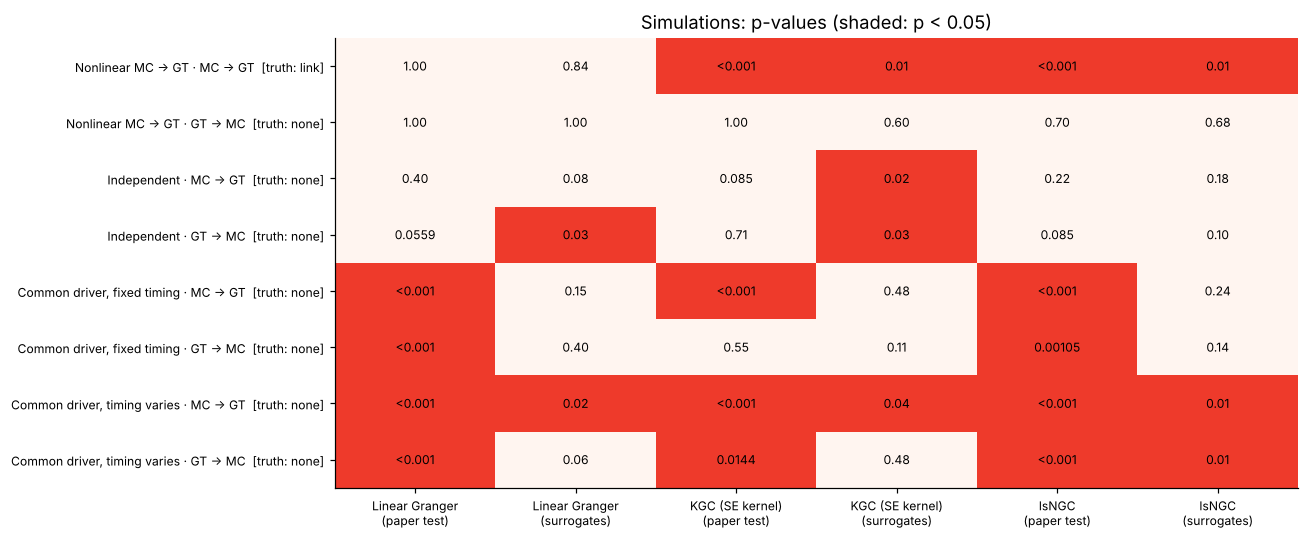

In [3]:
def pvalue_grid(ax, P, rows, cols, title):
    ax.imshow(np.where(np.isnan(P), 1, P) < ALPHA, cmap="Reds", vmin=0, vmax=1.6, aspect="auto")
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            ax.text(j, i, fmt_p(P[i, j]), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(len(cols)), cols, fontsize=8)
    ax.set_yticks(range(len(rows)), rows, fontsize=8)
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(12, 5))
pvalue_grid(ax, sim[[c for c, _ in TESTS]].to_numpy(float),
            [f"{r.scenario} · {r.direction}  [truth: {'link' if r.truth else 'none'}]" for r in sim.itertuples()],
            [t for _, t in TESTS], "Simulations: p-values (shaded: p < 0.05)")
fig.tight_layout()
fig.savefig(FIG_DIR / "kg01_simulation_single.png", dpi=200, bbox_inches="tight")

### 2.2 Rejection rates over 12 simulated datasets per scenario

In [4]:
rate_jobs = [(sc, e, c, lab, seed) for sc in S.SCENARIOS for e, c, lab in DIRS for seed in RATE_SEEDS]
rates_raw = cached("sim_rates", lambda: pd.DataFrame(Parallel(n_jobs=N_JOBS)(
    delayed(sim_one)(sc, e, c, lab, N_SURR_RATE, seed=seed) for sc, e, c, lab, seed in rate_jobs)))

rate_names = {c: t.replace("\n", " ") for c, t in TESTS}
rate_table = (rates_raw.assign(**{c: rates_raw[c] < ALPHA for c in rate_names})
              .groupby(["scenario", "direction", "truth"], sort=False)[list(rate_names)].mean()
              .rename(columns=rate_names))
rate_table.to_csv(TAB_DIR / "kernel_granger_simulation_rates.csv")
rate_table.round(2)

[sim_rates] loaded from cache


Linear Granger (paper test)  Linear Granger (surrogates)  KGC (SE kernel) (paper test)  KGC (SE kernel) (surrogates)  lsNGC (paper test)  \
scenario                     direction truth                                                                                                                                             
Nonlinear MC → GT            MC → GT   True                          0.08                         0.17                          1.00                          1.00                1.00   
                             GT → MC   False                         0.08                         0.08                          0.00                          0.08                0.00   
Independent                  MC → GT   False                         0.08                         0.00                          0.00                          0.08                0.00   
                             GT → MC   False                         0.00                         0.00                          0.00                          0.00                0.00   
Common driver, fixed timing  MC → GT   False                         1.00                         0.00                          0.92                          0.00                1.00   
                             GT → MC   False                         1.00                         0.08                          0.50                          0.00                0.75   
Common driver, timing varies MC → GT   False                         1.00                         0.92                          1.00                          0.83                1.00   
                             GT → MC   False                         1.00                         0.50                          0.58                          0.25                0.67   

                                              lsNGC (surrogates)  
scenario                     direction truth                      
Nonlinear MC → GT            MC → GT   True                 1.00  
                             GT → MC   False                0.00  
Independent                  MC → GT   False                0.00  
                             GT → MC   False                0.00  
Common driver, fixed timing  MC → GT   False                0.00  
                             GT → MC   False                0.08  
Common driver, timing varies MC → GT   False                0.92  
                             GT → MC   False                0.25

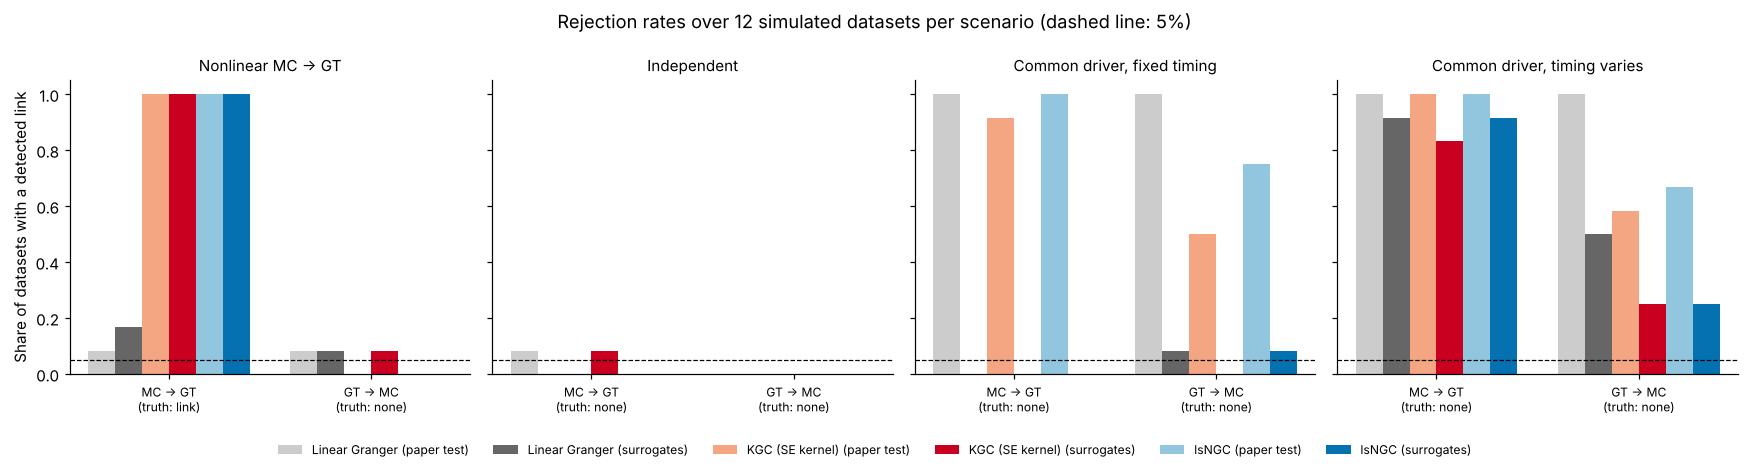

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
colors = ["#cccccc", "#666666", "#f4a582", "#ca0020", "#92c5de", "#0571b0"]
names = list(rate_names.values())
for ax, sc in zip(axes, S.SCENARIOS):
    sub = rate_table.loc[sc]
    x = np.arange(len(sub))
    w = 0.8 / len(names)
    for j, (nm, col) in enumerate(zip(names, colors)):
        ax.bar(x + (j - len(names) / 2 + 0.5) * w, sub[nm], w, color=col, label=nm)
    ax.axhline(ALPHA, color="black", lw=0.8, ls="--")
    ax.set_xticks(x, [f"{d}\n(truth: {'link' if t else 'none'})" for d, t in sub.index], fontsize=8)
    ax.set_title(sc, fontsize=10)
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Share of datasets with a detected link")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=8, frameon=False)
fig.suptitle(f"Rejection rates over {len(RATE_SEEDS)} simulated datasets per scenario (dashed line: 5%)")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG_DIR / "kg02_simulation_rates.png", dpi=200, bbox_inches="tight")

**What the simulations show** (12 datasets per scenario):

* **Power.** KGC (SE kernel) and lsNGC detect the quadratic MC → GT link in 12/12 datasets,
  with or without surrogates. Linear Granger causality detects it in 1–2/12: the link exists
  but has no linear correlation.
* **No link.** Every test declares a link in at most 1/12 datasets, which is consistent
  with a 5% level.
* **Common driver with fixed timing.** The paper tests declare a link in 50–100% of the
  datasets, although there is none. With season-swap surrogates this drops to 0–1/12.
* **Common driver whose timing changes every year.** All tests, including the surrogate
  tests, still declare links (25–92% of datasets). No test in this notebook can separate
  this situation from a real link.

For real data, the paper tests therefore cannot be trusted on their own, the surrogate
tests remove the effect of a fixed campaign calendar, and any link they find could still
come from events whose date varies from year to year.

## 3. Real data: lag order

The lag order $m$ is chosen for each effect series from its **own** past only (without the
cause), by leave-one-season-out cross-validation of a kernel ridge model, so that the
choice of $m$ cannot favour finding causality. All orders are compared on the same days
(from day 7 of each window).

In [6]:
data = {c: load_daily(c) for c in CODES}

lag_cv = cached("lag_cv", lambda: {
    (c, lab, cond): K.select_lag(data[c], e, a, LAGS, conditional=cond)
    for c in CODES for e, a, lab in DIRS for cond in (False, True)})

best_m = {k: int(v.idxmin()) for k, v in lag_cv.items()}
pd.DataFrame({"unconditional": {f"{LABEL[c]} · {lab}": best_m[c, lab, False] for c in CODES for _, _, lab in DIRS},
              "calendar-conditioned": {f"{LABEL[c]} · {lab}": best_m[c, lab, True] for c in CODES for _, _, lab in DIRS}})

[lag_cv] loaded from cache


,unconditional,calendar-conditioned
Dry January · MC → GT,2,3
Dry January · GT → MC,1,1
Mars Bleu · MC → GT,7,3
Mars Bleu · GT → MC,7,7
Movember · MC → GT,5,2
Movember · GT → MC,7,5
Octobre Rose · MC → GT,2,2
Octobre Rose · GT → MC,5,3


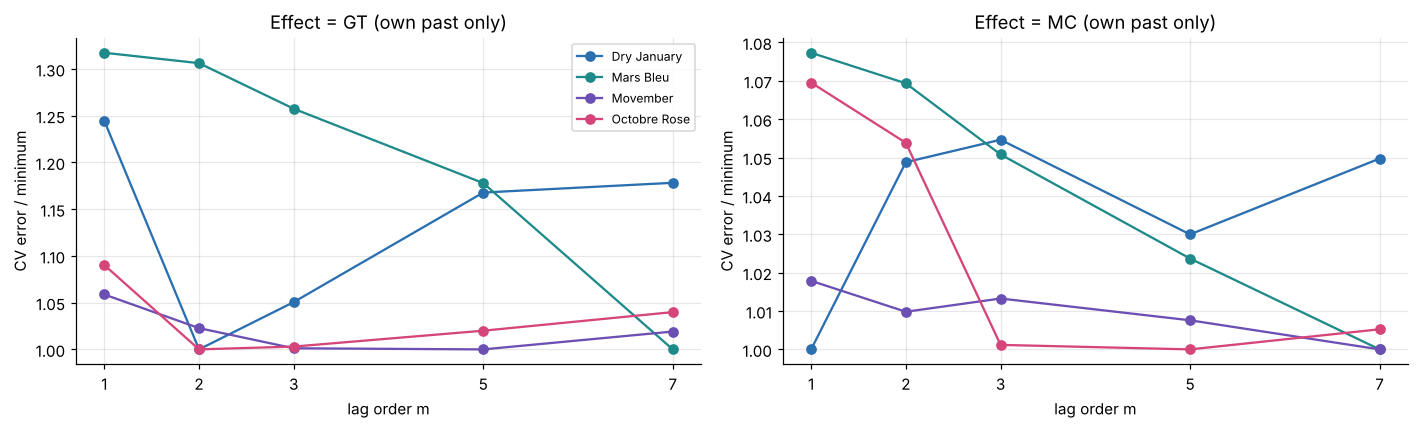

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (e, a, lab) in zip(axes, DIRS):
    for c in CODES:
        s = lag_cv[c, lab, False]
        ax.plot(s.index, s / s.min(), marker="o", color=CAMPAIGNS[c].color, label=LABEL[c])
    ax.set(title=f"Effect = {'GT' if e == 'gt' else 'MC'} (own past only)", xlabel="lag order m",
           ylabel="CV error / minimum", xticks=LAGS)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "kg03_lag_selection.png", dpi=200, bbox_inches="tight")

## 4. Real data: tests

For each campaign, direction and variant, KGC (linear and SE kernels) and lsNGC are run
with their parametric tests and with 199 season-swap surrogates.

In [8]:
main_jobs = [(c, e, a, lab, cond) for cond in (False, True) for c in CODES for e, a, lab in DIRS]


def real_one(c, e, a, lab, cond, seed):
    r = K.run_tests(data[c], e, a, m=best_m[c, lab, cond], conditional=cond, start=START,
                    n_surrogates=N_SURR, seed=seed)
    return {"campaign": LABEL[c], "direction": lab,
            "variant": "calendar-conditioned" if cond else "unconditional", **r}


main_raw = cached("main", lambda: Parallel(n_jobs=N_JOBS)(
    delayed(real_one)(*j, seed=1000 + i) for i, j in enumerate(main_jobs)))
main = pd.DataFrame([strip(r) for r in main_raw])

for k in METHODS:
    adj_param = K.benjamini_hochberg if k == "lsngc" else K.holm
    main[f"{k}_p_param_adj"] = main.groupby("variant")[f"{k}_p_param"].transform(lambda p: adj_param(p))
    main[f"{k}_p_surr_adj"] = main.groupby("variant")[f"{k}_p_surr"].transform(lambda p: K.holm(p))
main.to_csv(TAB_DIR / "kernel_granger_main.csv", index=False)

show = ["campaign", "direction", "variant", "m", "n",
        "kgc_se_delta", "kgc_se_null_mean", "kgc_se_n_f", "kgc_se_p_param_adj", "kgc_se_p_surr_adj",
        "lsngc_delta", "lsngc_null_mean", "lsngc_p_param_adj", "lsngc_p_surr_adj",
        "kgc_lin_p_param_adj", "kgc_lin_p_surr_adj"]
main[show].round(4)

[main] loaded from cache


,campaign,direction,variant,m,n,kgc_se_delta,kgc_se_null_mean,kgc_se_n_f,kgc_se_p_param_adj,kgc_se_p_surr_adj,lsngc_delta,lsngc_null_mean,lsngc_p_param_adj,lsngc_p_surr_adj,kgc_lin_p_param_adj,kgc_lin_p_surr_adj
0,Dry January,MC → GT,unconditional,2,396,0.3015,0.2141,1,0.1309,0.70,0.0499,0.0229,0.0014,0.400,0.0017,0.260
1,Dry January,GT → MC,unconditional,1,396,0.2239,0.1598,3,0.0000,0.70,0.1193,0.0693,0.0000,0.390,0.0000,0.090
2,Mars Bleu,MC → GT,unconditional,7,891,0.1977,0.1970,0,0.4682,1.00,0.0041,0.0115,0.5362,1.000,1.0000,1.000
3,Mars Bleu,GT → MC,unconditional,7,891,0.2158,0.2086,0,0.4624,1.00,0.0101,0.0057,0.0891,0.520,0.0178,0.040
4,Movember,MC → GT,unconditional,5,935,0.1918,0.1487,1,0.1089,0.12,0.0265,0.0060,0.0001,0.040,0.2681,0.070
5,Movember,GT → MC,unconditional,7,935,0.1721,0.1925,1,0.0067,1.00,0.0341,0.0257,0.0000,0.385,0.0000,0.090
6,Octobre Rose,MC → GT,unconditional,2,924,0.1312,0.1523,3,0.0000,1.00,0.0032,0.0157,0.5733,1.000,1.0000,1.000
7,Octobre Rose,GT → MC,unconditional,5,924,0.3123,0.3249,4,0.0010,1.00,0.0364,0.0522,0.0000,1.000,0.0001,1.000
8,Dry January,MC → GT,calendar-conditioned,3,396,0.3346,0.4341,1,0.0376,1.00,0.0299,0.0219,0.0497,1.000,0.0513,0.480
9,Dry January,GT → MC,calendar-conditioned,1,396,0.1628,0.1664,1,0.1020,1.00,0.0221,0.0282,0.1118,1.000,0.0000,0.040


### 4.1 Summary of the evidence

Each cell is an adjusted p-value (shaded when < 0.05). The paper tests do not account for
the shared campaign calendar; the surrogate tests do (for a fixed calendar).

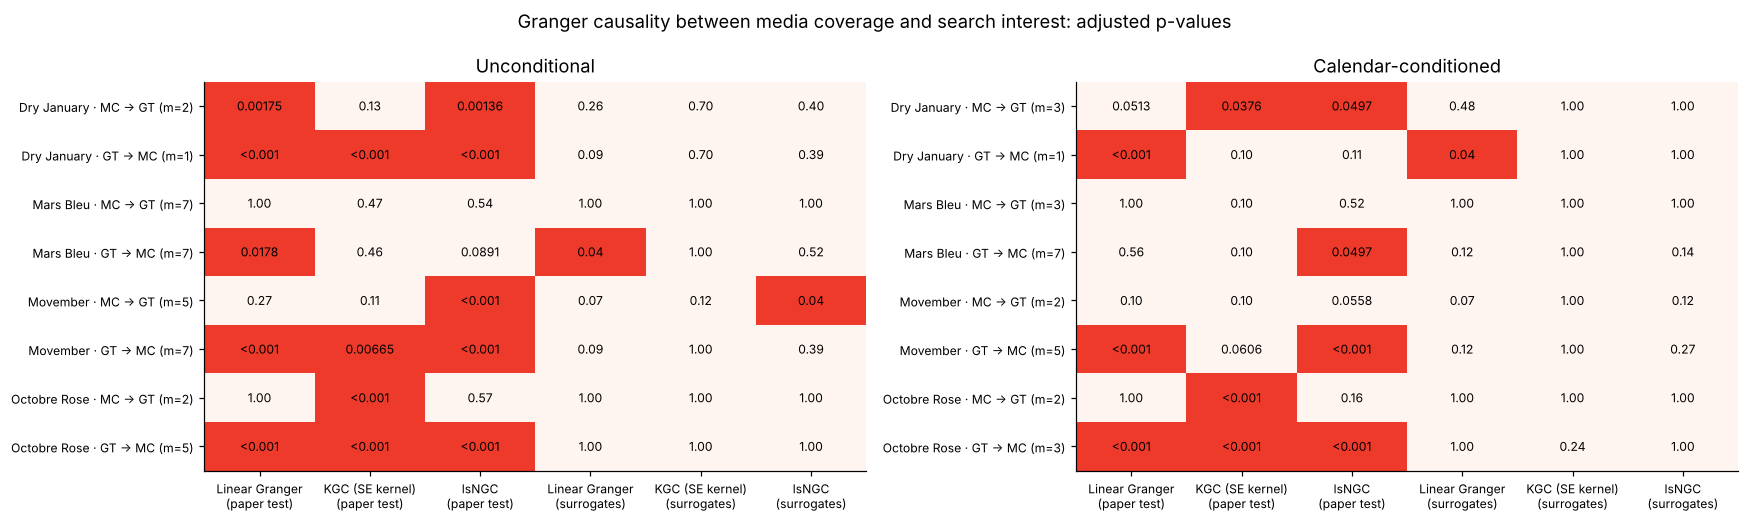

In [9]:
SUMMARY = ([(f"{k}_p_param_adj", f"{v}\n(paper test)") for k, v in METHODS.items()]
           + [(f"{k}_p_surr_adj", f"{v}\n(surrogates)") for k, v in METHODS.items()])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, var in zip(axes, ["unconditional", "calendar-conditioned"]):
    sub = main[main["variant"] == var].reset_index(drop=True)
    pvalue_grid(ax, sub[[c for c, _ in SUMMARY]].to_numpy(float),
                [f"{r.campaign} · {r.direction} (m={r.m})" for r in sub.itertuples()],
                [t for _, t in SUMMARY], var.capitalize())
fig.suptitle("Granger causality between media coverage and search interest: adjusted p-values")
fig.tight_layout()
fig.savefig(FIG_DIR / "kg04_main_results.png", dpi=200, bbox_inches="tight")

### 4.2 Observed statistic against its surrogate distribution

Red line: share of the restricted model's unexplained variance captured by the real cause
($\delta$). Histogram: the same statistic for 199 surrogate causes taken from other seasons.

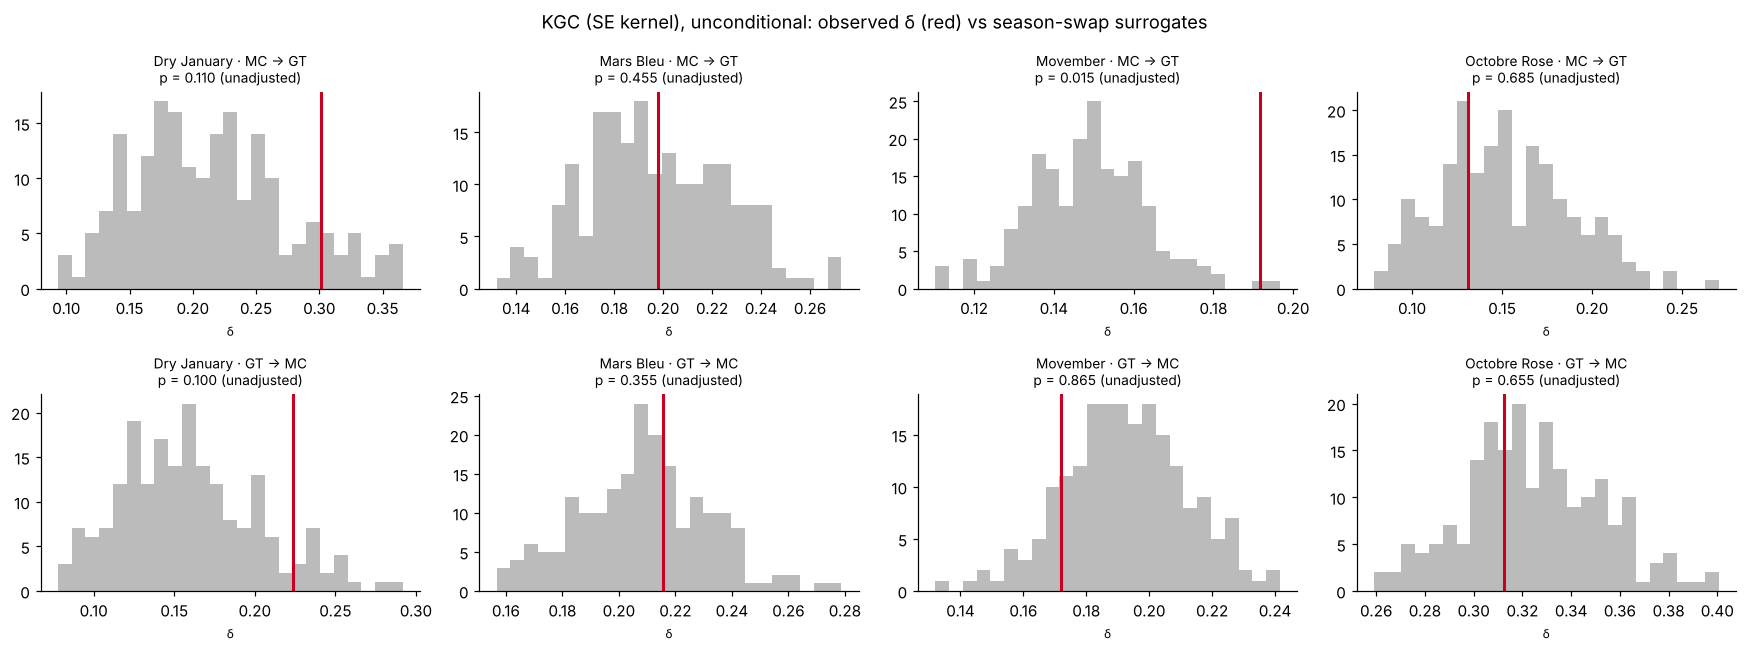

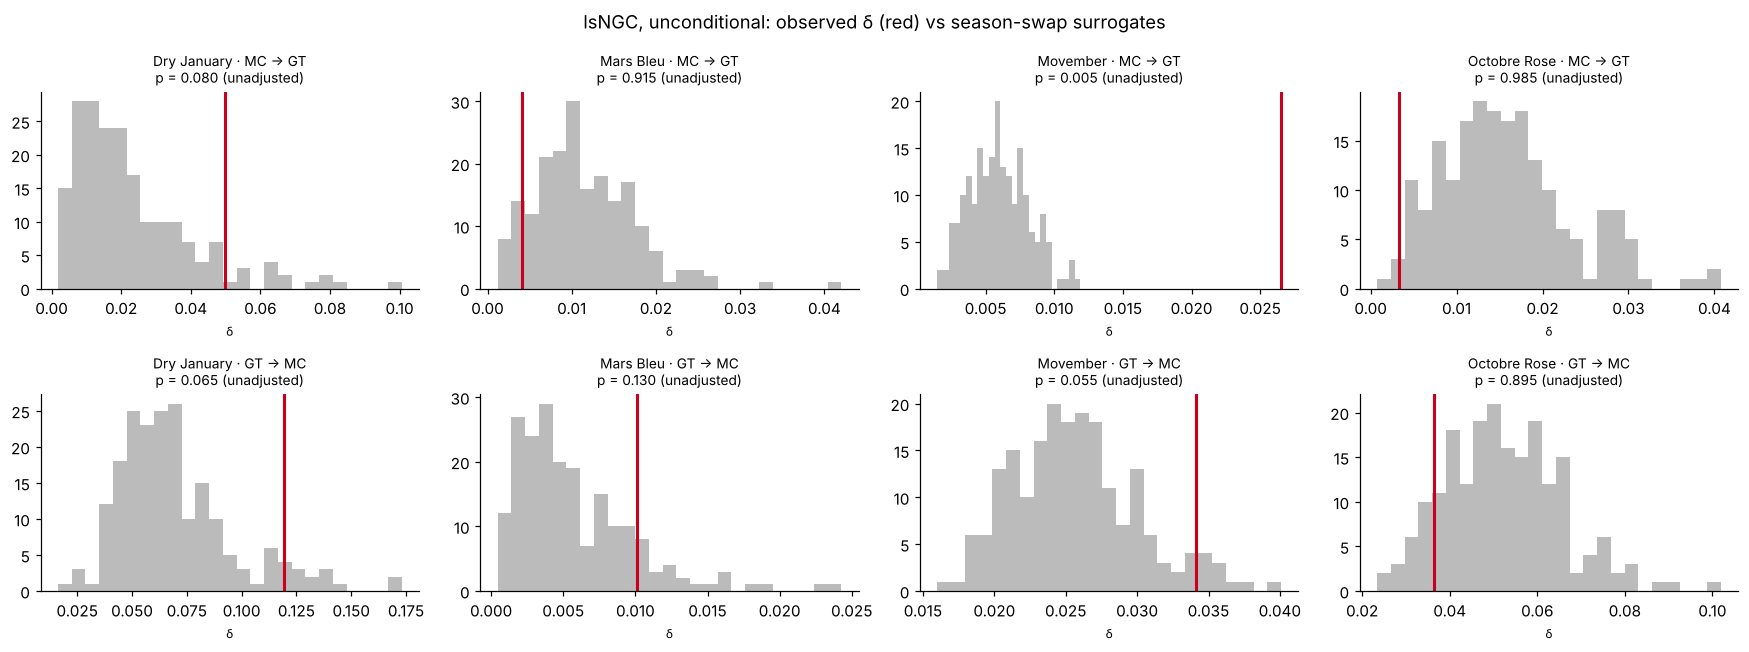

In [10]:
for key in ("kgc_se", "lsngc"):
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))
    for ax, r in zip(axes.T.flat, [r for r in main_raw if not r["conditional"]]):
        obs, null = r["nulls"][key]
        ax.hist(null, bins=25, color="#bbbbbb")
        ax.axvline(obs, color="#ca0020", lw=2)
        ax.set_title(f"{r['campaign']} · {r['direction']}\np = {K.surrogate_pvalue(obs, null):.3f} (unadjusted)",
                     fontsize=9)
        ax.set_xlabel("δ", fontsize=8)
    fig.suptitle(f"{METHODS[key]}, unconditional: observed δ (red) vs season-swap surrogates")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kg05_null_{key}.png", dpi=200, bbox_inches="tight")

## 5. Sensitivity to the lag order

Both nonlinear methods with surrogates for every lag order, unconditional variant
(39 surrogates, unadjusted p-values, resolution 0.025). A robust link should not depend
on one particular $m$.

[lag_sensitivity] loaded from cache


kgc_se                              lsngc                            
m                           1      2      3      5      7      1      2      3      5      7
campaign     direction                                                                      
Dry January  GT → MC    0.050  0.050  0.125  0.375  0.350  0.100  0.150  0.200  0.275  0.100
             MC → GT    0.025  0.175  0.575  0.875  0.950  0.100  0.100  0.225  0.600  0.425
Mars Bleu    GT → MC    0.325  0.525  0.050  0.450  0.325  0.075  0.450  0.150  0.675  0.025
             MC → GT    0.825  0.850  0.800  0.475  0.425  0.750  1.000  0.900  0.875  0.825
Movember     GT → MC    0.050  0.075  0.175  0.375  0.850  0.025  0.025  0.050  0.025  0.050
             MC → GT    0.075  0.300  0.050  0.025  0.025  0.025  0.025  0.025  0.025  0.025
Octobre Rose GT → MC    0.500  0.050  0.125  0.750  0.950  0.775  0.925  0.625  0.900  0.775
             MC → GT    0.750  0.750  0.750  0.650  0.700  0.175  1.000  1.000  0.950  0.575

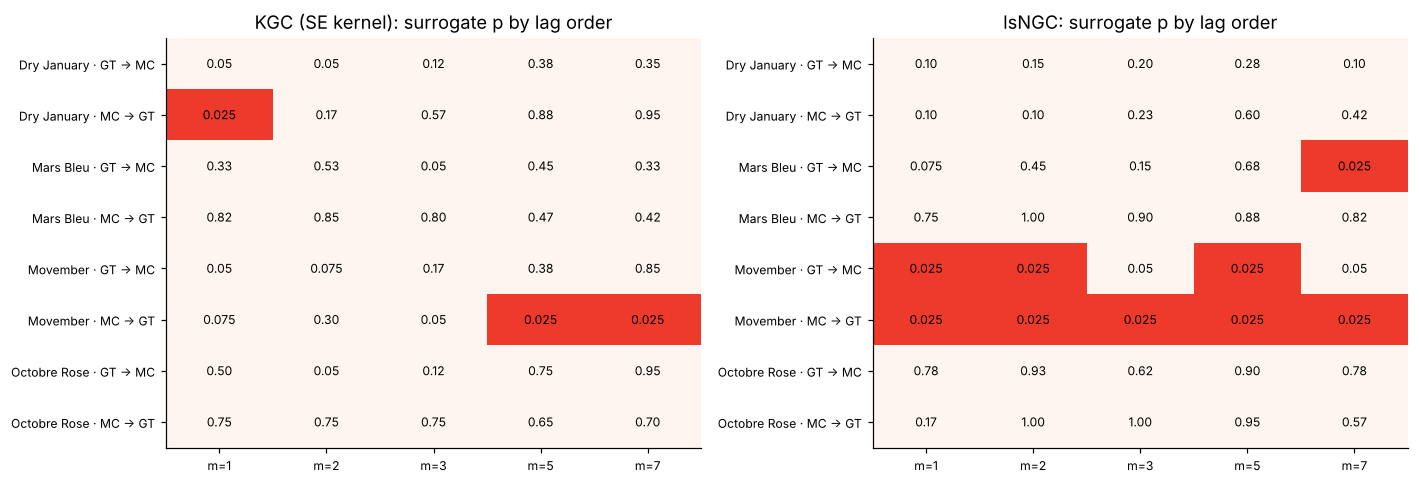

In [11]:
sens_jobs = [(c, e, a, lab, m) for c in CODES for e, a, lab in DIRS for m in LAGS]


def sens_one(c, e, a, lab, m):
    r = K.run_tests(data[c], e, a, m=m, start=START, n_surrogates=N_SURR_RATE, seed=m,
                    methods=("kgc_se", "lsngc"))
    return {"campaign": LABEL[c], "direction": lab, "m": m,
            "kgc_se": r["kgc_se_p_surr"], "lsngc": r["lsngc_p_surr"]}


sens = cached("lag_sensitivity", lambda: pd.DataFrame(Parallel(n_jobs=N_JOBS)(
    delayed(sens_one)(*j) for j in sens_jobs)))
sens.to_csv(TAB_DIR / "kernel_granger_lag_sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key in zip(axes, ("kgc_se", "lsngc")):
    sp = sens.pivot_table(index=["campaign", "direction"], columns="m", values=key)
    pvalue_grid(ax, sp.to_numpy(float), [f"{a} · {b}" for a, b in sp.index],
                [f"m={m}" for m in sp.columns], f"{METHODS[key]}: surrogate p by lag order")
fig.tight_layout()
fig.savefig(FIG_DIR / "kg06_lag_sensitivity.png", dpi=200, bbox_inches="tight")
sens.pivot_table(index=["campaign", "direction"], columns="m", values=["kgc_se", "lsngc"]).round(3)

## 6. Conclusions

**1. The paper tests find links almost everywhere.** In the unconditional variant, at least
one of the three paper tests is significant for 7 of the 8 campaign × direction pairs
(all except Mars Bleu MC → GT). The simulations show that a shared calendar alone
produces this.

**2. Against season-swap surrogates, one nonlinear link survives correction for multiple
testing: Movember, MC → GT.**
* lsNGC: the real coverage series beats all 199 surrogates (unadjusted p = 0.005,
  Holm-adjusted p = 0.040).
* It holds at every lag order from 1 to 7 days with lsNGC (p = 0.025, the smallest value
  possible with 39 surrogates). KGC (SE kernel) agrees at 4 of the 5 lag orders
  (p ≤ 0.075, and 0.025 at 5 and 7 days) but not at 2 days (p = 0.30).
* The effect is small: coverage explains 2.7% of the variance left unexplained by past
  searches, against 0.6% on average for surrogates.
* With calendar conditioning it points the same way but no longer survives correction
  (unadjusted p = 0.015, adjusted p = 0.12).
* The reverse direction (GT → MC) is borderline with lsNGC (unadjusted p between 0.025
  and 0.055 across lag orders) and not significant after correction.

**3. Octobre Rose shows no link beyond the calendar,** although its paper tests are the
most significant (p < 0.001). The real coverage series predicts searches no better than
coverage from other years: for GT → MC, KGC gives δ = 0.312 against 0.325 on average for
surrogates. This matches notebook 02: the media and search peaks fall within two days of
each other in 9 of 11 seasons, which is what a fixed date (1 October) driving both
series produces.

**4. Dry January and Mars Bleu give only isolated signals.** Linear Granger with
surrogates is significant once in each:
* Mars Bleu GT → MC, unconditional: adjusted p = 0.040 (0.12 when calendar-conditioned);
* Dry January GT → MC, calendar-conditioned: adjusted p = 0.040 (0.09 unconditional).

Neither is confirmed by the nonlinear methods or by the other variant, so neither should
be presented as a finding.

**Interpretation.** Most of the Granger causality between media coverage and search
interest found in notebook 03, linear or not, is explained by the campaign calendar
shared by both series. The only robust candidate is Movember, where day-to-day coverage
helps predict searches beyond the calendar. This differs from the peak timing of
notebook 02, where the Movember media peak comes about 9 days after the search peak. The
link remains predictive, not causal: events whose date changes from year to year (news,
celebrity posts, local initiatives) could drive both series, and the simulations show
that no test here can rule this out.